# Day 002 — Share of visits booked more than 14 days out, by clinic and modality

**Business question:** In a six-clinic primary care network, how often do patients have to book more than two weeks ahead, and does that access gap differ by clinic and by visit modality (in person, video, audio-only)?

**Definition:** long-lead share = scheduled visits with `lead_days > 14` ÷ all scheduled visits, where `lead_days` = visit date − booked date. Completed, no-show, and cancelled visits all count, because the booking window is set when the slot is booked.

All rows come from the seeded synthetic database in `shared/clinic.db`. They describe no real patients, providers, or clinics.

In [1]:
from pathlib import Path
import sqlite3
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("../..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from shared.sqlutil import split_named_queries

DB = ROOT / "shared" / "clinic.db"
assert DB.exists(), f"Database not found: {DB}"
conn = sqlite3.connect(DB)

# Run the same named queries that run_all.py exports to results/.
queries = dict(split_named_queries(Path("query.sql").read_text(encoding="utf-8")))
q = {name: pd.read_sql(sql, conn) for name, sql in queries.items()}
sorted(q)

['by_clinic',
 'by_modality',
 'by_year_modality',
 'clinic_by_modality',
 'in_person_c05_vs_peers',
 'in_person_c05_vs_peers_by_visit_type',
 'in_person_no_show_by_booking_window',
 'lead_band_by_modality',
 'lead_days_check',
 'lead_percentiles_by_modality',
 'overall']

## Network view and data check

In [2]:
display(q["overall"])
display(q["lead_days_check"])

,scheduled_visits,booked_over_14_days,pct_over_14_days,avg_lead_days
0,49538,14909,30.1,10.5


,scheduled_visits,mismatched_rows,booked_after_visit,min_lead_days,max_lead_days
0,49538,0,0,0,47


## By modality

In [3]:
display(q["by_modality"])
display(q["lead_percentiles_by_modality"])
display(q["lead_band_by_modality"].pivot(index="lead_band", columns="modality", values="pct_of_modality").fillna(0.0))
display(q["by_year_modality"].pivot(index="year", columns="modality", values="pct_over_14_days"))

,modality,scheduled_visits,booked_over_14_days,pct_over_14_days,avg_lead_days
0,in_person,36005,14488,40.2,12.5
1,video,9289,329,3.5,5.4
2,audio,4244,92,2.2,5.0


,modality,scheduled_visits,median_lead_days,p90_lead_days
0,in_person,36005,12,23
1,video,9289,5,11
2,audio,4244,4,9


modality,audio,in_person,video
lead_band,,,
1: 0-3 days,38.4,18.8,36.1
2: 4-7 days,40.5,13.8,40.0
3: 8-14 days,18.9,27.2,20.4
4: 15-28 days,2.2,35.9,3.5
5: 29+ days,0.0,4.4,0.0


modality,audio,in_person,video
year,,,
2024,1.7,40.5,3.7
2025,2.6,40.0,3.4


## By clinic, and clinic × modality

In [4]:
display(q["by_clinic"])
display(q["clinic_by_modality"].pivot(index="clinic_id", columns="modality", values="pct_over_14_days"))
display(q["in_person_c05_vs_peers"])
display(q["in_person_c05_vs_peers_by_visit_type"].pivot(index="visit_type", columns="clinic_group", values="pct_over_14_days"))

,clinic_id,clinic_name,scheduled_visits,booked_over_14_days,pct_over_14_days,avg_lead_days
0,C05,Brookfield Medical Group,8352,5472,65.5,19.6
1,C01,Maple Street Primary Care,8775,2054,23.4,8.7
2,C04,Lakeside Family Practice,8537,1970,23.1,8.7
3,C03,Cedar Hollow Clinic,7941,1829,23.0,8.7
4,C02,Oakridge Family Medicine,8309,1905,22.9,8.7
5,C06,Pine Ridge Clinic,7624,1679,22.0,8.5


modality,audio,in_person,video
clinic_id,,,
C01,0.0,32.3,0.0
C02,0.0,31.4,0.0
C03,0.0,31.6,0.0
C04,0.0,31.5,0.0
C05,15.3,84.2,18.8
C06,0.0,30.2,0.0


,clinic_group,scheduled_visits,booked_over_14_days,pct_over_14_days,avg_lead_days
0,C05 Brookfield,6001,5051,84.2,22.9
1,Peer clinics,30004,9437,31.5,10.4


clinic_group,C05 Brookfield,Peer clinics
visit_type,,
acute,49.8,0.0
chronic_followup,96.9,40.7
new_patient,99.2,60.8
preventive,97.7,39.8


## Why it matters: in-person no-show rate by booking window

In [5]:
q["in_person_no_show_by_booking_window"]

,booking_window,eligible_visits,no_shows,no_show_rate_pct
0,14_days_or_less,19638,3250,16.5
1,over_14_days,13070,3368,25.8


## Chart

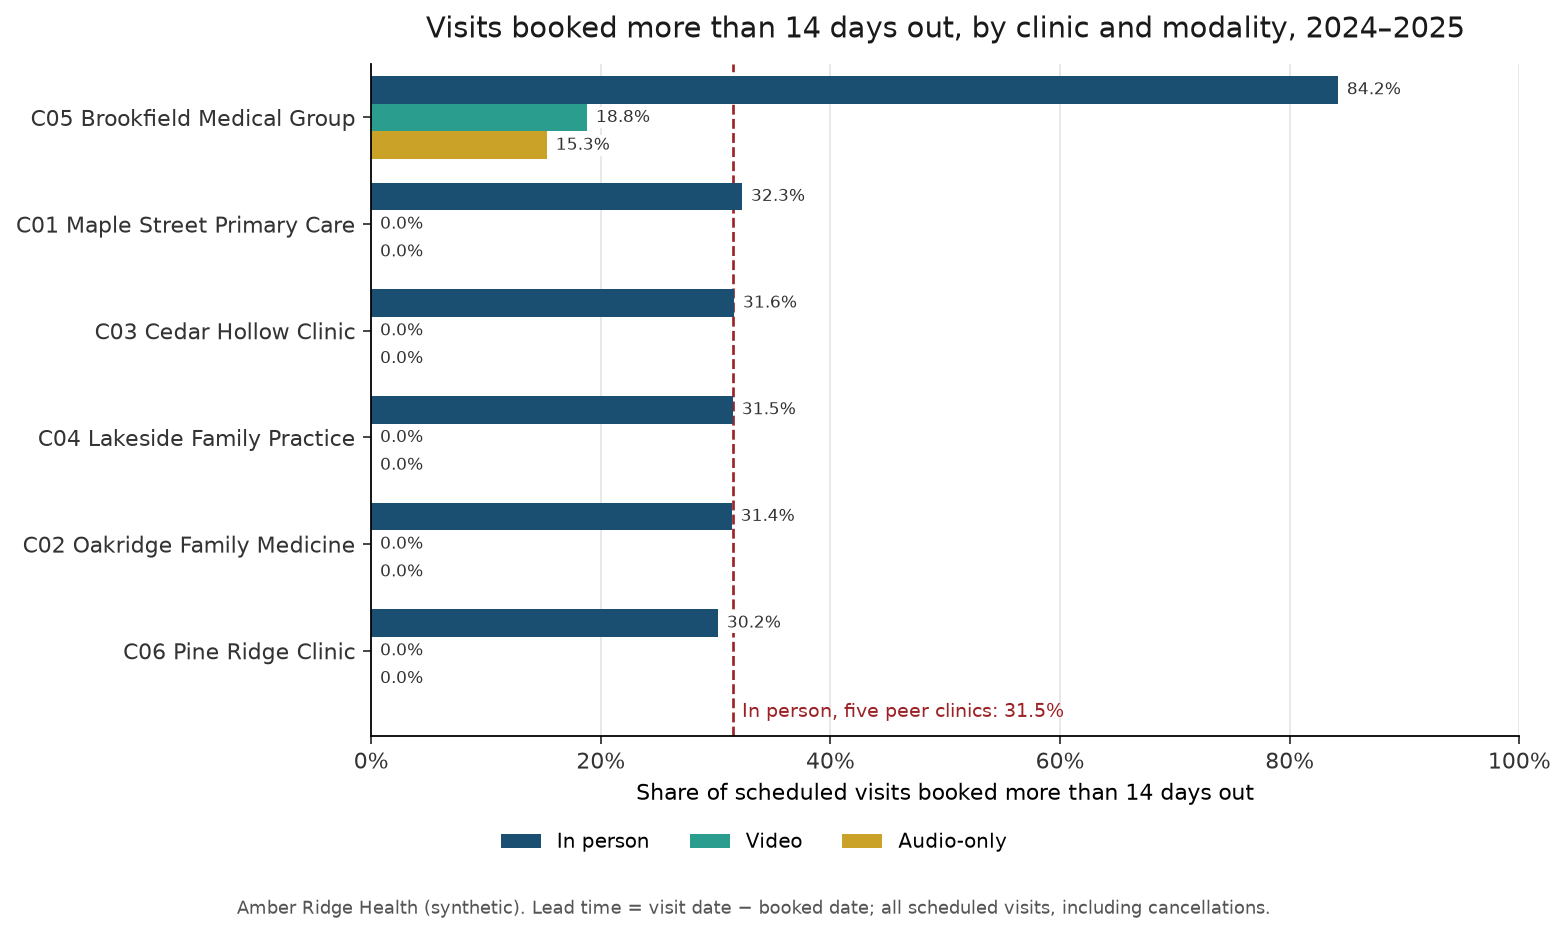

In [6]:
cm = q["clinic_by_modality"].copy()
in_person = cm[cm["modality"] == "in_person"]
clinic_order = in_person.sort_values("pct_over_14_days")["clinic_id"].tolist()  # highest at top
names = q["by_clinic"].set_index("clinic_id")["clinic_name"]
modalities = ["in_person", "video", "audio"]
labels = {"in_person": "In person", "video": "Video", "audio": "Audio-only"}
colors = {"in_person": "#1b4f72", "video": "#2a9d8f", "audio": "#c9a227"}
peer_in_person = float(q["in_person_c05_vs_peers"].set_index("clinic_group").loc["Peer clinics", "pct_over_14_days"])

fig, ax = plt.subplots(figsize=(10.4, 6.0), dpi=160)
bar_h = 0.26
for i, mod in enumerate(modalities):
    vals = cm[cm["modality"] == mod].set_index("clinic_id").loc[clinic_order, "pct_over_14_days"]
    ys = [y + (1 - i) * bar_h for y in range(len(clinic_order))]
    ax.barh(ys, vals.values, height=bar_h, color=colors[mod], label=labels[mod])
    for y, v in zip(ys, vals.values):
        ax.annotate(f"{v:.1f}%", xy=(v, y), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=7.8, color="#333333",
                    bbox=dict(boxstyle="square,pad=0.1", facecolor="white", edgecolor="none"))

ax.axvline(peer_in_person, color="#9b2226", linestyle="--", linewidth=1.2, zorder=0.5)
ax.text(peer_in_person + 0.8, -0.62,
        f"In person, five peer clinics: {peer_in_person:.1f}%", color="#9b2226", fontsize=8.5)

ax.set_ylim(-0.8, len(clinic_order) - 0.5)
ax.set_yticks(range(len(clinic_order)))
ax.set_yticklabels([f"{c} {names[c]}" for c in clinic_order])
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _pos: f"{v:.0f}%"))
ax.set_xlabel("Share of scheduled visits booked more than 14 days out")
ax.set_title("Visits booked more than 14 days out, by clinic and modality, 2024–2025",
             fontsize=13, pad=12, color="#1a1a1a")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(colors="#333333")
ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
ax.set_axisbelow(True)

handles, labs = ax.get_legend_handles_labels()
fig.legend(handles, labs, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 0.06), fontsize=9)
fig.text(0.5, 0.015,
         "Amber Ridge Health (synthetic). Lead time = visit date − booked date; all scheduled visits, including cancellations.",
         ha="center", fontsize=8, color="#555555")
fig.subplots_adjust(bottom=0.2, left=0.27, right=0.96, top=0.90)
fig.savefig("chart.png", facecolor="white")
plt.show()

## Takeaway

- **30.1%** of all scheduled visits were booked more than 14 days out, but almost all of that is in-person demand: **40.2%** of in-person visits versus **3.5%** video and **2.2%** audio-only.
- Brookfield (C05) is the access outlier: **84.2%** of its in-person visits are booked more than 14 days out, against **31.5%** at the five peer clinics. It is also the only clinic where video and audio visits book that far ahead.
- Long lead times carry a cost: in-person visits booked more than 14 days out no-show at **25.8%**, versus **16.5%** when booked within two weeks.

A clinic manager should fix Brookfield's in-person template first, and at the other sites use video for routine follow-ups when the next in-person slot is more than two weeks away.

In [7]:
conn.close()